# Preprocessing

Use this notebook for visual checks on the saved TRAIN split.

1. Run **Shared setup** and **Shared display and evidence helpers** once per kernel.
2. Run **Select new random TRAIN images** whenever you want new examples.
3. Rerun the comparison cells for the operations you want to see.
4. Optionally run **Save operation evidence** to save the comparisons you just ran.

Previous cell outputs stay visible until those cells are rerun. The selected IDs and original-image preview show which sample the next comparison will use.

In [41]:
# Shared setup
import csv
import json
import os
import random
import sys
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter

import matplotlib
import matplotlib.pyplot as plt
from PIL import __version__ as pillow_version
import numpy as np

cwd = Path.cwd().resolve()
project_root = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "data" / "manifests" / "train.csv").is_file()
        and (path / "src" / "data_loader.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start the kernel in the project directory or its notebooks/ folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_rgb
from src.preprocessing.mean_filter import mean_filter
from src.preprocessing.gaussian_filter import gaussian_filter
from src.preprocessing.median_filter import median_filter
from src.preprocessing.contrast_stretching import contrast_stretch
from src.preprocessing.histogram_equalisation import histogram_equalise
from src.preprocessing.resize import resize_rgb
from src.preprocessing.intensity_normalisation import normalise_intensity

raw_root = project_root / Path(os.environ.get("PET_RAW_ROOT", "data/raw")).expanduser()
train_manifest = project_root / "data" / "manifests" / "train.csv"

In [43]:
# Shared display and evidence helpers
def count_rgb_values(image_rgb):
    """Accumulate one count per pixel in the bin for its uint8 intensity."""
    counts = np.zeros((3, 256), dtype=np.int64)
    for channel in range(3):
        np.add.at(counts[channel], image_rgb[..., channel].ravel(), 1)
    return counts


def show_rgb_comparison(image_id, variants):
    """Compare images and their RGB counts on common histogram scales."""
    height, width = variants[0][1].shape[:2]
    figure, axes = plt.subplots(
        2, len(variants), squeeze=False, figsize=(3.6 * len(variants), 6.5),
        gridspec_kw={"height_ratios": (3, 2)}, layout="constrained",
    )
    figure.suptitle(f"{image_id} | Original dimensions: {width} × {height} pixels")
    for index, (title, image_rgb) in enumerate(variants):
        image_axis, hist_axis = axes[:, index]
        image_axis.imshow(image_rgb)
        image_axis.set_title(title)
        image_axis.set_axis_off()

        if index:
            hist_axis.sharex(axes[1, 0])
            hist_axis.sharey(axes[1, 0])
            hist_axis.tick_params(labelleft=False)
        for counts, colour, name in zip(
            count_rgb_values(image_rgb),
            ("#c63c44", "#218752", "#3269ba"),
            ("Red", "Green", "Blue"),
        ):
            hist_axis.plot(np.arange(256), counts, color=colour, label=name, linewidth=1.2)
        hist_axis.set_xlabel("Pixel intensity")
        hist_axis.set_xlim(0, 255)
        hist_axis.set_ylim(bottom=0)

    # Set the shared upper limit after plotting all channels in all variants.
    peak = max(line.get_ydata().max() for axis in axes[1] for line in axis.lines)
    axes[1, 0].set_ylim(0, peak * 1.05)
    axes[1, 0].set_ylabel("Pixel count")
    axes[1, 0].legend(fontsize="small")
    plt.show()
    return figure


def save_comparison_evidence(operation, comparisons, settings):
    """Save figures already displayed and the settings used to produce them."""
    destination = project_root / "results" / "preprocessing" / operation
    destination.mkdir(parents=True, exist_ok=True)
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    examples = []
    for figures, record in comparisons:
        separate_figures = isinstance(figures, dict)
        named = figures if separate_figures else {"comparison": figures}
        saved_figures = {}
        for name, figure in named.items():
            suffix = f"_{name}" if separate_figures else ""
            filename = f"{timestamp}_{record['image_id']}{suffix}.png"
            with (destination / filename).open("xb") as stream:
                figure.savefig(stream, format="png", dpi=150)
            saved_figures[name] = filename
        if separate_figures:
            examples.append({**record, "figures": saved_figures})
        else:
            examples.append({**record, "figure": saved_figures["comparison"]})

    summary = destination / f"{timestamp}_summary.json"
    with summary.open("x", encoding="utf-8") as stream:
        json.dump({
            "scope": "TRAIN", "operation": operation, **settings,
            "software_versions": {
                "Python": sys.version.split()[0], "NumPy": np.__version__,
                "Pillow": pillow_version, "Matplotlib": matplotlib.__version__,
            },
            "selected_image_ids": [example["image_id"] for example in examples],
            "examples": examples,
        }, stream, indent=2)
        stream.write("\n")
    return summary


def close_comparison_figures(figures):
    for figure in (figures.values() if isinstance(figures, dict) else (figures,)):
        plt.close(figure)


def clear_train_figures():
    """Close figures owned by the previous sample without clearing cell outputs."""
    for comparisons, _ in globals().pop("comparison_results", {}).values():
        for figures, _ in comparisons:
            close_comparison_figures(figures)
    previous_preview = globals().pop("train_sample_preview", None)
    if previous_preview is not None:
        plt.close(previous_preview)


def show_train_preview(sample):
    preview = sample[:6]
    columns = min(3, len(preview))
    rows = (len(preview) + columns - 1) // columns
    figure, axes = plt.subplots(
        rows, columns, squeeze=False, figsize=(2.6 * columns, 2.4 * rows), layout="constrained",
    )
    figure.suptitle(f"Original images ({len(preview)} of {len(sample)})")
    for axis in axes.flat:
        axis.set_axis_off()
    for axis, (image_id, image) in zip(axes.flat, preview):
        axis.imshow(image)
        axis.set_title(image_id, fontsize="small")
    plt.show()
    return figure


def compare_on_train(operation, variants, settings, *, render=None):
    """Apply each variant to the original sample and retain the displayed evidence."""
    if not globals().get("train_comparison_sample"):
        raise RuntimeError("Run Select new random TRAIN images first.")
    previous = comparison_results.pop(operation, None)
    if previous is not None:
        for figures, _ in previous[0]:
            close_comparison_figures(figures)
    comparisons = []
    for sample_index, (image_id, original) in enumerate(train_comparison_sample):
        height, width = original.shape[:2]
        views = [("Original", original)]
        timings = []
        print(f"\n{image_id} | {width} × {height} pixels")
        for title, apply_filter, parameters in variants:
            started = perf_counter()
            processed = apply_filter(original, **parameters)
            seconds = perf_counter() - started
            views.append((title, processed))
            timings.append({"variant": title, **parameters, "filter_seconds": seconds})
            print(f"  {title}: {seconds * 1_000:.2f} ms")

        if render is None:
            figures, extra = show_rgb_comparison(image_id, views), {}
        else:
            figures, extra = render(image_id, views, sample_index)
        comparisons.append((figures, {
            **extra,
            "image_id": image_id, "original_width": width,
            "original_height": height, "timings": timings,
        }))
    comparison_results[operation] = comparisons, settings


def save_train_comparison(operation):
    """Save a displayed operation for the current TRAIN sample."""
    result = globals().get("comparison_results", {}).get(operation)
    if result is None:
        raise RuntimeError(f"Display {operation} for the current TRAIN sample before saving it.")
    comparisons, settings = result
    processed_ids = [record["image_id"] for _, record in comparisons]
    current_ids = [image_id for image_id, _ in globals().get("train_comparison_sample", ())]
    if processed_ids != current_ids:
        raise RuntimeError(f"Rerun {operation} for the current TRAIN sample before saving it.")
    summary = save_comparison_evidence(operation, comparisons, settings)
    print(f"Saved comparison figures and {summary.relative_to(project_root).as_posix()}")

## Select new random TRAIN images

Set the number of examples in the next cell. Each run reads the saved TRAIN manifest and draws distinct IDs for all operation sections. Consecutive runs can coincidentally repeat some images. Loading happens here, outside operation timing.

Choosing a sample clears the cached comparisons. Rerun an operation for the current sample before saving it. Each comparison starts from the same original RGB arrays, with 256 intensity bins and shared histogram axes. These displays are for correctness and visual exploration. Breed recognition performance requires evaluation on VAL.

Selected TRAIN images: saint_bernard_109, Persian_114, Bengal_112


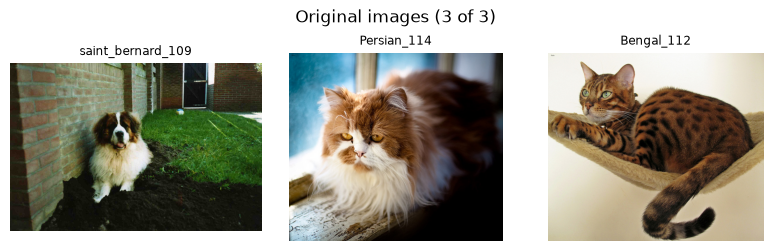

In [31]:
# Select new random TRAIN images
number_of_examples = 3

train_comparison_sample = ()
clear_train_figures()
comparison_results = {}

with train_manifest.open(encoding="utf-8", newline="") as stream:
    train_rows = list(csv.DictReader(stream))
train_ids = {row["image_id"] for row in train_rows}
if not train_rows or len(train_ids) != len(train_rows) or any(row["split"] != "train" for row in train_rows):
    raise ValueError(f"Expected a nonempty TRAIN manifest with unique image IDs: {train_manifest}")
if type(number_of_examples) is not int or not 1 <= number_of_examples <= len(train_rows):
    raise ValueError(f"Choose a whole number of examples between 1 and {len(train_rows):,}.")

selected_rows = random.sample(train_rows, k=number_of_examples)
train_comparison_sample = tuple(
    (row["image_id"], load_rgb(raw_root / row["image_relative_path"]))
    for row in selected_rows
)
print("Selected TRAIN images:", ", ".join(image_id for image_id, _ in train_comparison_sample))

train_sample_preview = show_train_preview(train_comparison_sample)

## Mean filtering

A 3×3 mean filter replaces each pixel with the average of its nine neighbouring values, including the centre. This smooths local intensity changes and can soften edges. The filter averages red, green, and blue independently in float64. It reflects the interior at image borders without repeating the edge pixel, then applies NumPy's rounding to nearest with ties to even, clips to 0–255, and returns a uint8 RGB array at the original resolution.

For the example below, the centre covers the values 1 through 9, so its mean is 45/9 = 5. At the top-left corner, reflection gives the rows (5, 4, 5), (2, 1, 2), and (5, 4, 5). The mean is 33/9, which rounds to 4.

In [32]:
example_plane = np.arange(1, 10, dtype=np.uint8).reshape(3, 3)
example_rgb = np.repeat(example_plane[..., None], 3, axis=2)
example_filtered = mean_filter(example_rgb, kernel_size=3)

print(f"Centre: expected 5, calculated {example_filtered[1, 1, 0]}")
print(f"Top-left corner: expected 4, calculated {example_filtered[0, 0, 0]}")

Centre: expected 5, calculated 5
Top-left corner: expected 4, calculated 4


### Compare the shared TRAIN images

Edit the mean kernel sizes here. Run **Select new random TRAIN images** when you want different images, then rerun this comparison.


saint_bernard_109 | 500 × 332 pixels
  Mean 3 × 3: 11.13 ms
  Mean 5 × 5: 6.56 ms
  Mean 7 × 7: 6.62 ms


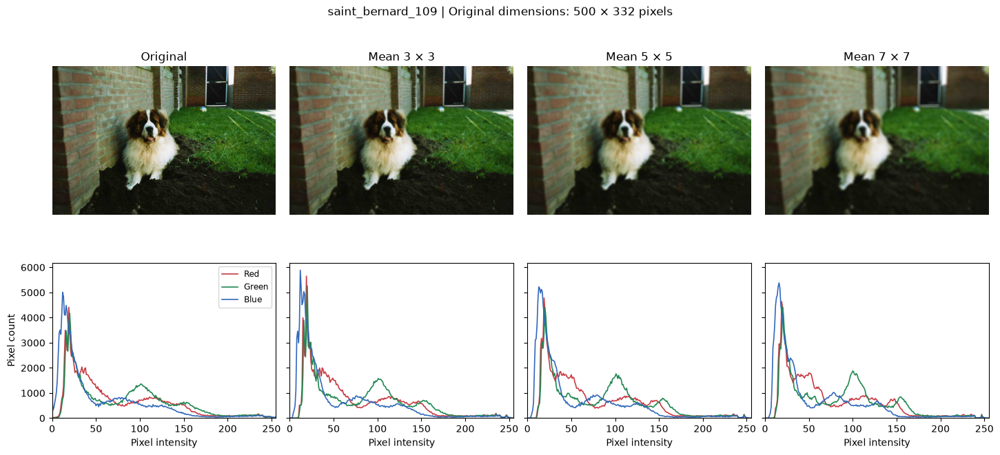


Persian_114 | 500 × 439 pixels
  Mean 3 × 3: 8.76 ms
  Mean 5 × 5: 8.35 ms
  Mean 7 × 7: 9.14 ms


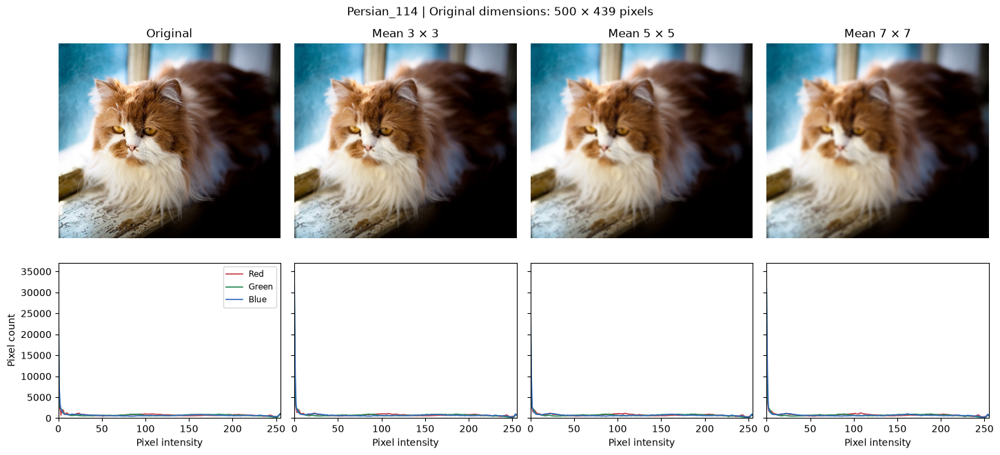


Bengal_112 | 500 × 436 pixels
  Mean 3 × 3: 9.98 ms
  Mean 5 × 5: 10.08 ms
  Mean 7 × 7: 10.16 ms


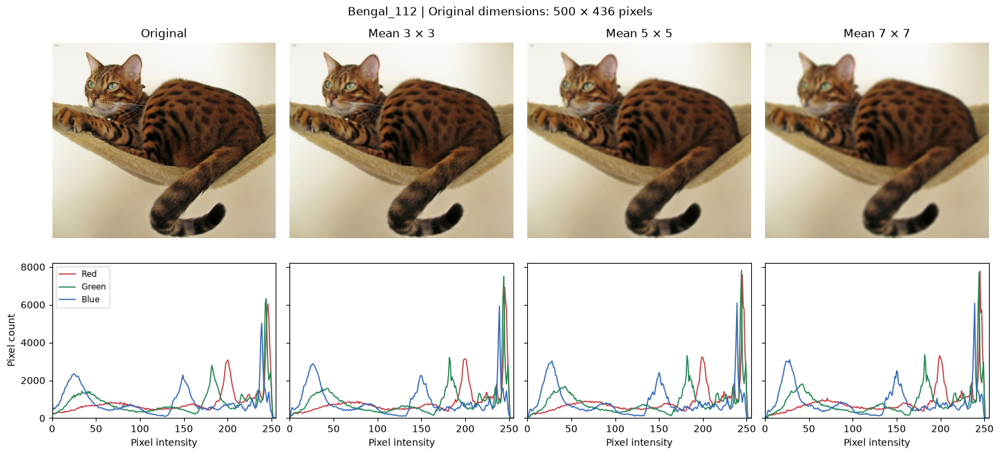

In [33]:
kernel_sizes = [3, 5, 7]
if not kernel_sizes:
    raise ValueError("Choose at least one mean kernel size.")

compare_on_train(
    "mean_filter",
    [(f"Mean {size} × {size}", mean_filter, {"kernel_size": size}) for size in kernel_sizes],
    {
        "kernel_sizes": list(kernel_sizes),
        "padding": "NumPy reflect",
        "rounding": "np.rint, then clip to [0, 255] and cast to uint8",
    },
)

### Save the displayed sample (optional)

Run this cell after the comparison if you want to keep the current figures and timing data. It saves timestamped evidence under results/preprocessing/mean_filter/ using the images already displayed.

In [17]:
save_train_comparison("mean_filter")

Saved comparison figures and results/preprocessing/mean_filter/20261122T131050_259913Z_summary.json


## Gaussian filtering

The finite Gaussian gives nearby pixels more weight, with symmetric weights that sum to one. Two one-dimensional passes apply the weights to each RGB channel with reflected borders. A larger sigma spreads the weights farther, which can suppress noise and soften detail. The comparison uses a 7 × 7 kernel for both settings.


saint_bernard_109 | 500 × 332 pixels
  Gaussian 7 × 7, σ=1: 15.30 ms
  Gaussian 7 × 7, σ=1.5: 15.52 ms


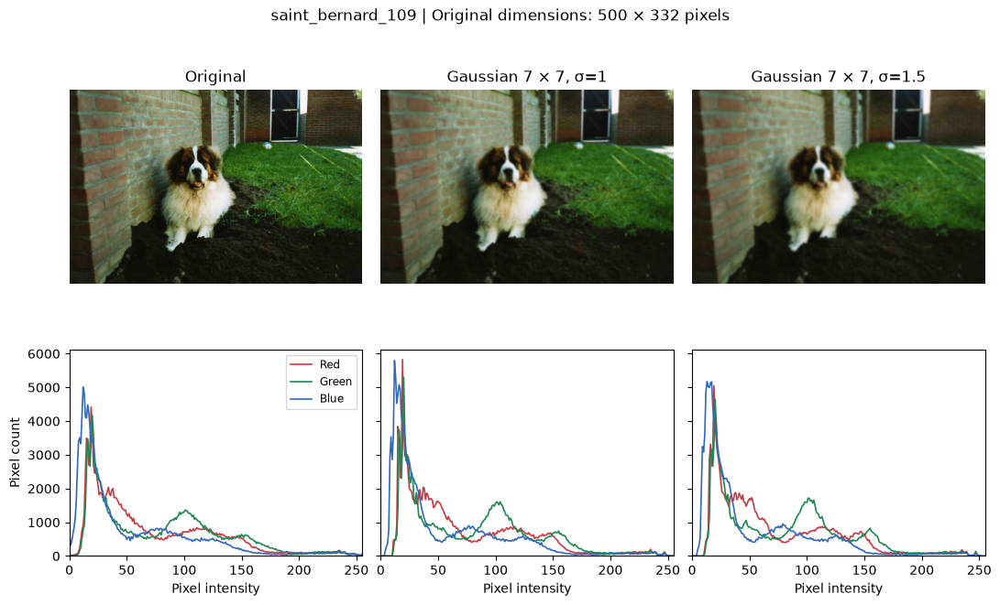


Persian_114 | 500 × 439 pixels
  Gaussian 7 × 7, σ=1: 20.13 ms
  Gaussian 7 × 7, σ=1.5: 22.44 ms


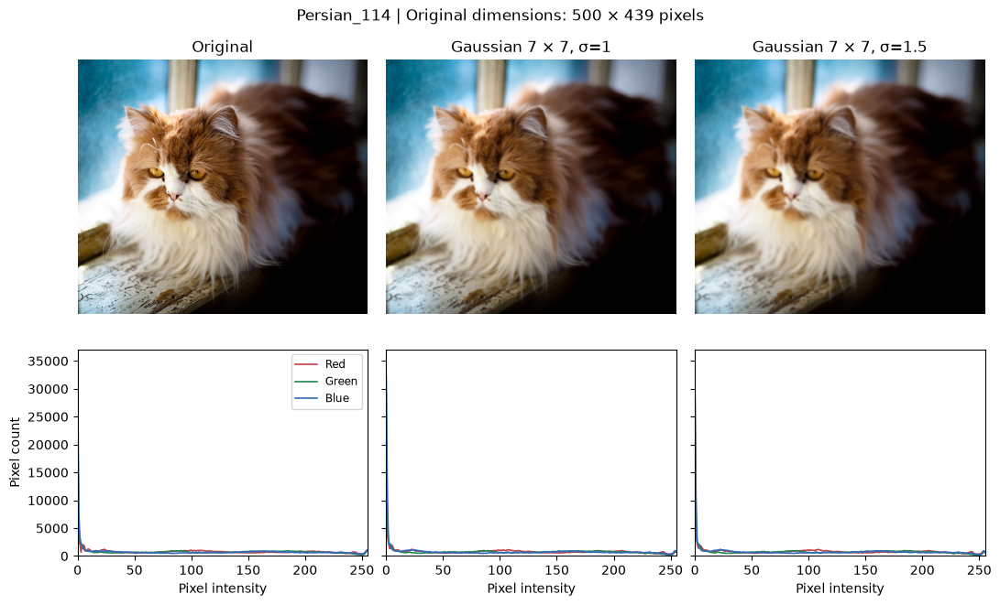


Bengal_112 | 500 × 436 pixels
  Gaussian 7 × 7, σ=1: 21.41 ms
  Gaussian 7 × 7, σ=1.5: 20.80 ms


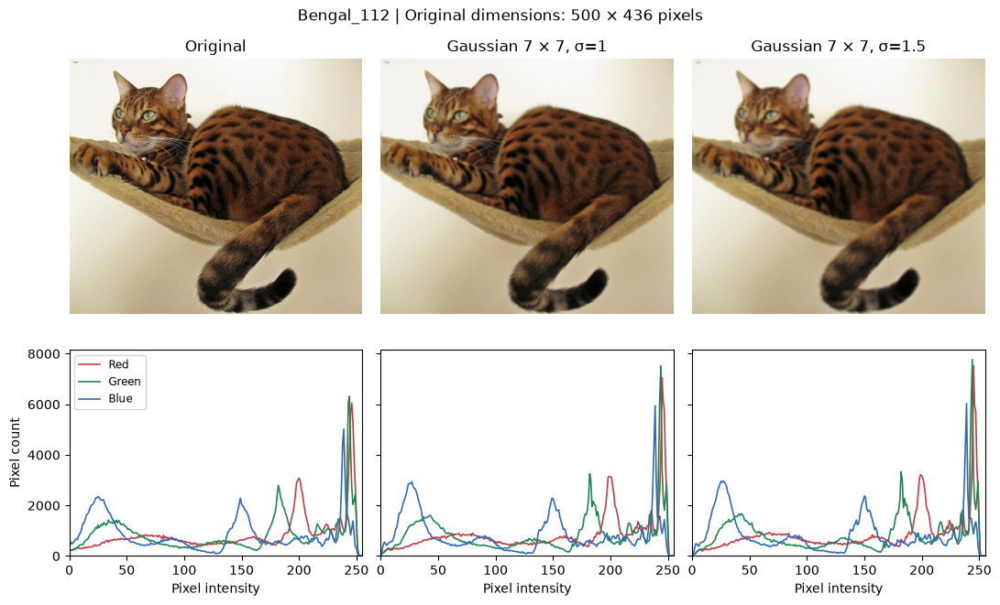

In [34]:
gaussian_size = 7
gaussian_sigmas = [1.0, 1.5]
compare_on_train(
    "gaussian_filter",
    [
        (f"Gaussian {gaussian_size} × {gaussian_size}, σ={sigma:g}", gaussian_filter,
         {"kernel_size": gaussian_size, "sigma": sigma})
        for sigma in gaussian_sigmas
    ],
    {"kernel_size": gaussian_size, "sigmas": list(gaussian_sigmas), "padding": "NumPy reflect"},
)

## Median filtering

The local median can remove isolated bright or dark pixels while retaining more of an edge than an average. It can also remove fine details. This implementation takes the median independently in each RGB channel, uses reflected borders, and processes small tiles to limit memory use.


saint_bernard_109 | 500 × 332 pixels
  Median 3 × 3: 85.51 ms


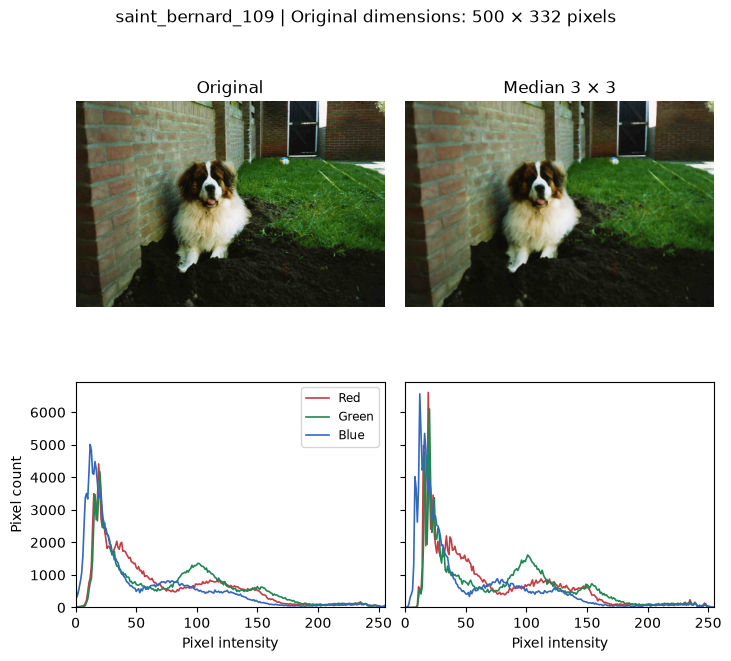


Persian_114 | 500 × 439 pixels
  Median 3 × 3: 87.38 ms


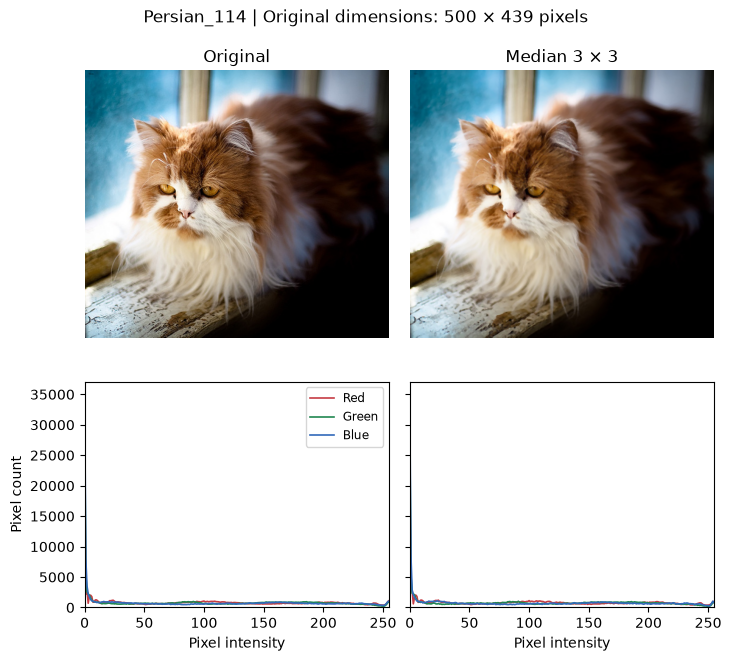


Bengal_112 | 500 × 436 pixels
  Median 3 × 3: 109.07 ms


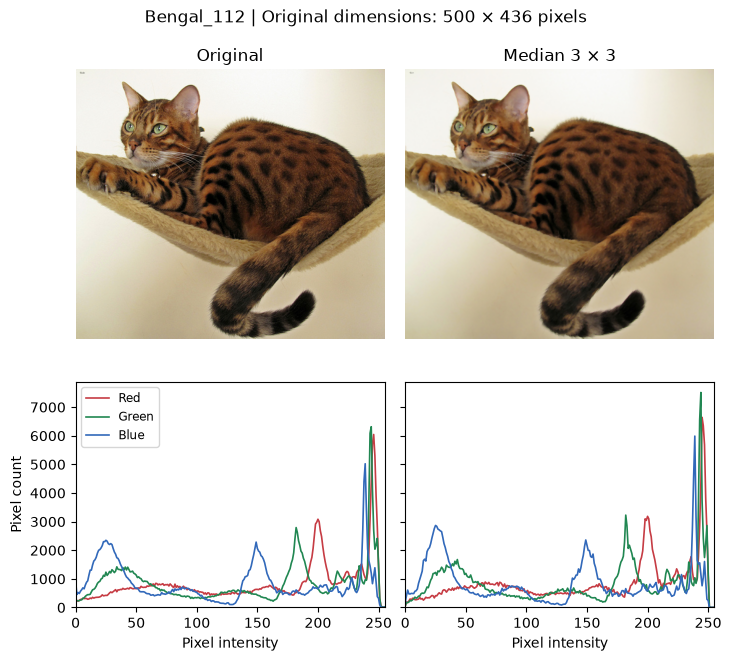

In [35]:
median_size = 3
compare_on_train(
    "median_filter",
    [(f"Median {median_size} × {median_size}", median_filter, {"kernel_size": median_size})],
    {"kernel_size": median_size, "padding": "NumPy reflect"},
)

## Contrast stretching

HSV describes colour by hue (H), saturation (S), and value (V). Matplotlib converts float64 RGB and HSV with channels on the 0–1 scale. V is the largest RGB component. The stretch maps a component's minimum and maximum to 0 and 255. HSV mode changes only V, while RGB mode stretches each channel independently and can shift colours. A constant channel stays unchanged. Constant V preserves the exact input RGB values. Outliers can limit the contrast gain for typical pixels.


saint_bernard_109 | 500 × 332 pixels
  Stretch HSV value: 61.52 ms
  Stretch RGB channels: 7.21 ms


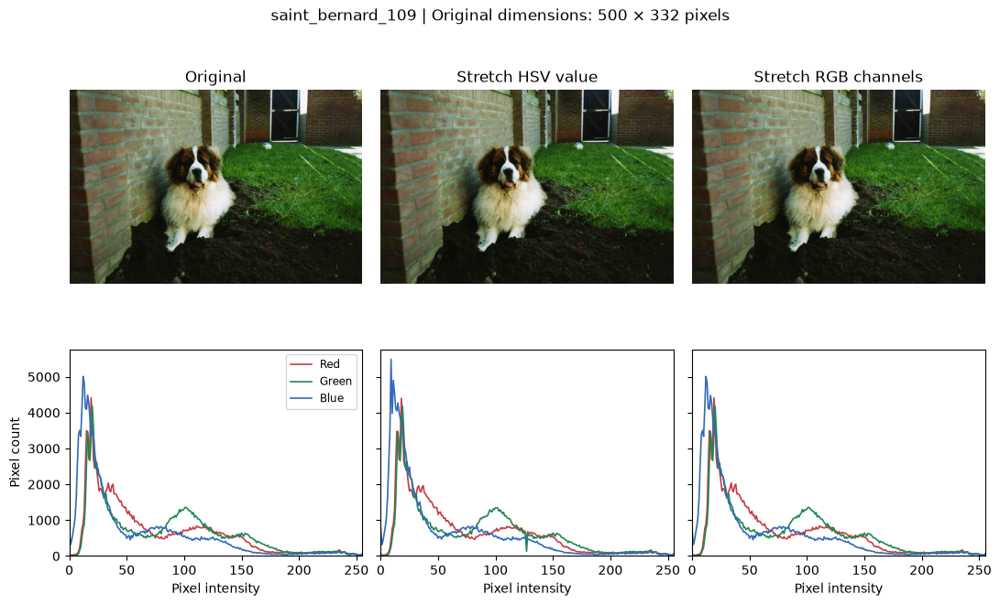


Persian_114 | 500 × 439 pixels
  Stretch HSV value: 67.94 ms
  Stretch RGB channels: 9.94 ms


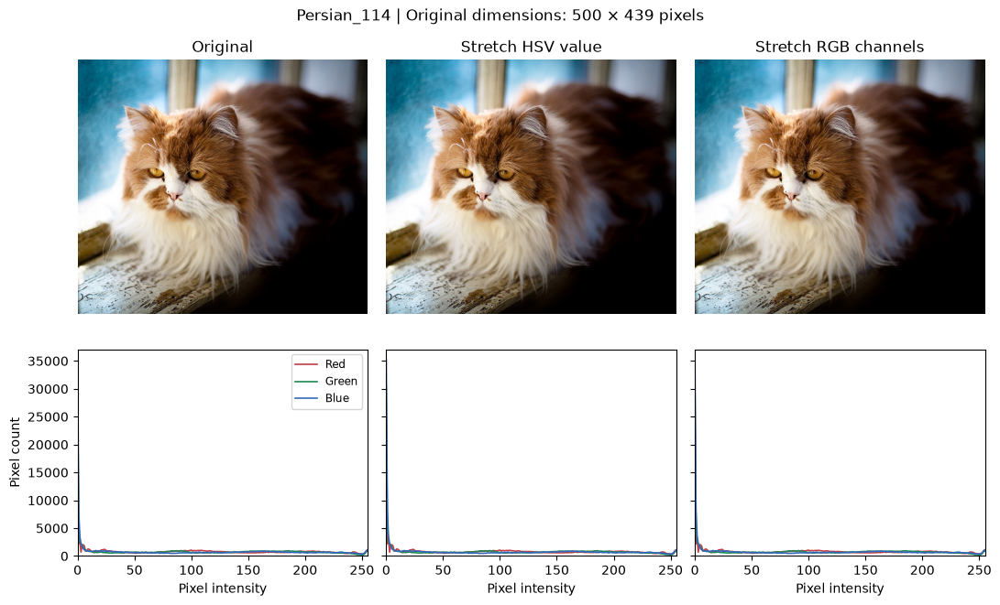


Bengal_112 | 500 × 436 pixels
  Stretch HSV value: 81.74 ms
  Stretch RGB channels: 11.53 ms


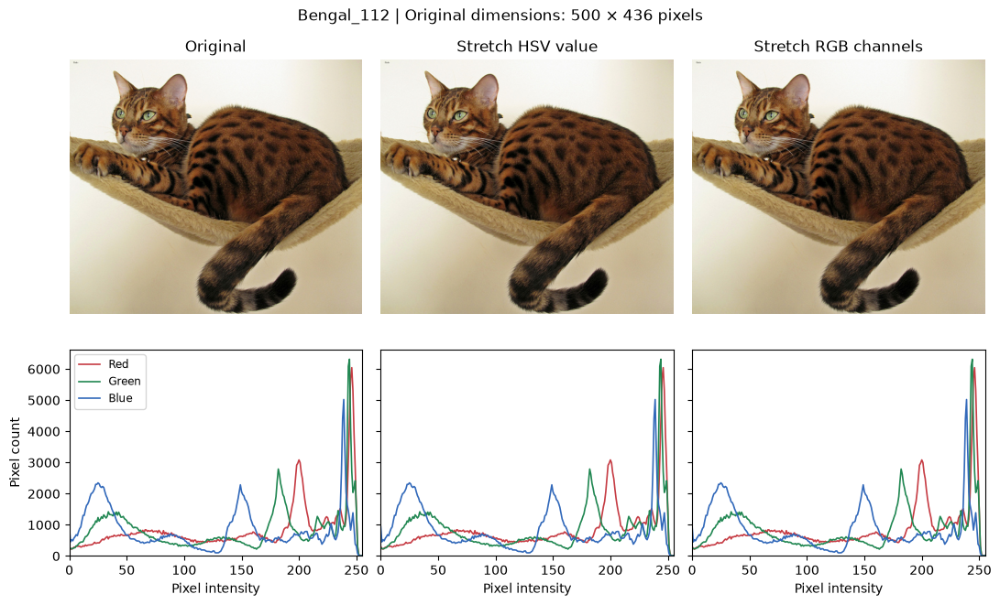

In [36]:
compare_on_train(
    "contrast_stretching",
    [
        ("Stretch HSV value", contrast_stretch, {"mode": "hsv_value"}),
        ("Stretch RGB channels", contrast_stretch, {"mode": "rgb_channels"}),
    ],
    {"modes": ["hsv_value", "rgb_channels"], "hsv_conversion": "Matplotlib float64, channels in [0, 1]"},
)

## Histogram equalisation

Equalisation redistributes HSV value levels using cumulative pixel counts. It builds a 256-bin V histogram by indexed addition and maps each value with 255 × (CDF − CDF_min) / (N − CDF_min), where CDF_min is the first occupied cumulative count and N is the total number of pixels. Constant V returns the original RGB values. Equalisation can reveal detail in a narrow intensity range, but it can also amplify noise or make shading look harsher.


saint_bernard_109 | 500 × 332 pixels
  Equalise HSV value: 66.85 ms


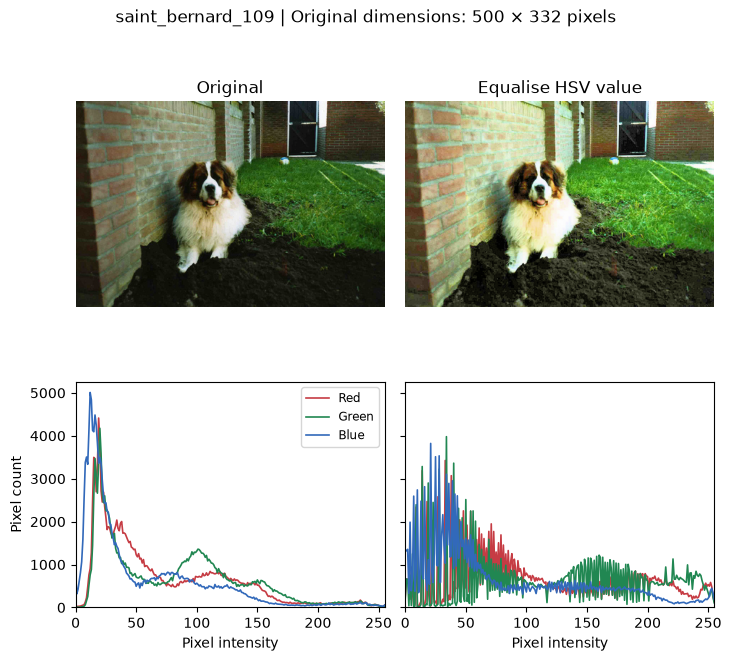


Persian_114 | 500 × 439 pixels
  Equalise HSV value: 73.00 ms


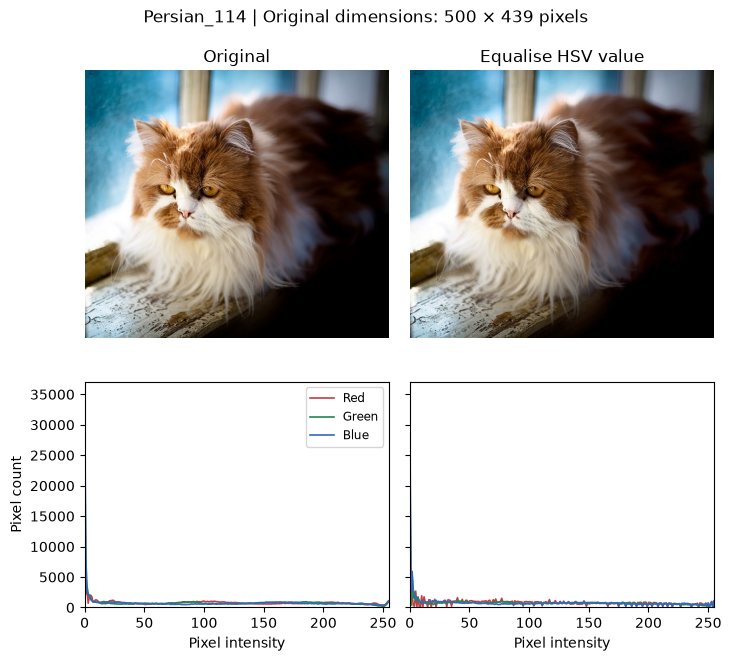


Bengal_112 | 500 × 436 pixels
  Equalise HSV value: 92.79 ms


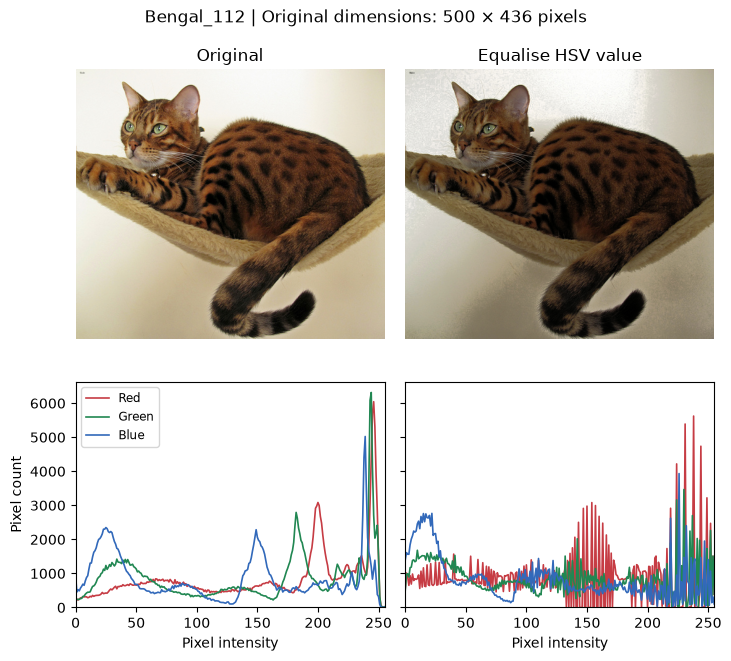

In [37]:
compare_on_train(
    "histogram_equalisation",
    [("Equalise HSV value", histogram_equalise, {})],
    {
        "component": "HSV V",
        "histogram_bins": 256,
        "cdf_baseline": "first occupied cumulative count",
        "hsv_conversion": "Matplotlib float64, channels in [0, 1]",
    },
)

## Resizing

Each output pixel corresponds to a position in the source. Nearest picks one source pixel, bilinear blends nearby pixels with linear weights, and bicubic uses a wider cubic kernel for smoother detail. Downsampling discards fine detail. Pillow's bilinear and bicubic resize filters expand their effective support when shrinking, while nearest samples one pixel. The function uses Pillow's direct resize path with reducing_gap=None. [Pillow resampling filters](https://pillow.readthedocs.io/en/stable/handbook/concepts.html#filters)

Interpolation determines how to compute pixel values. The aspect-ratio policy determines how to fit the image into the target. Stretch can distort shapes, pad introduces constant border pixels, and center crop can remove useful image regions. These changes can affect descriptors differently. Stretch with bilinear interpolation is the reference starting point and still needs evaluation.

For pad and center crop, the limiting axis matches the target, and the other axis rounds half up with a minimum of one pixel. Placement uses whole-pixel centring. Any extra padding or crop pixel goes on the right or bottom.

In [44]:
def show_resize_comparisons(image_id, views, sample_index):
    images = dict(views)
    original = images["Original"]
    height, width = original.shape[:2]
    interpolation_figure, axes = plt.subplots(
        len(resize_sizes), len(resize_methods), squeeze=False,
        figsize=(8.5, 8), layout="constrained",
    )
    interpolation_figure.suptitle(f"{image_id} | Stretch from {width} × {height} px")
    for row, size in enumerate(resize_sizes):
        for col, method in enumerate(resize_methods):
            axis = axes[row, col]
            axis.imshow(images[resize_title(size, method)], interpolation="nearest")
            axis.set_title(f"{method.title()} | {size} × {size} px")
            axis.set_axis_off()
    plt.show()

    geometry_figure, axes = plt.subplots(1, 4, figsize=(11, 3.3), layout="constrained")
    geometry_figure.suptitle(f"{image_id} | Geometry at {geometry_size} × {geometry_size} px, bilinear")
    labels = (("Original", "Original"), (resize_title(geometry_size, "bilinear"), "Stretch"),
              ("Pad", "Pad (black)"), ("Center crop", "Center crop"))
    for axis, (key, label) in zip(axes, labels):
        axis.imshow(images[key], interpolation="nearest")
        axis.set_title(label)
        axis.set_axis_off()
    plt.show()

    figures = {"interpolation": interpolation_figure, "geometry": geometry_figure}
    extra = {}
    if sample_index == 0:
        start, stop = detail_size * 3 // 8, detail_size * 5 // 8
        detail_figure, axes = plt.subplots(1, len(resize_methods), figsize=(8, 3), layout="constrained")
        detail_figure.suptitle(f"{image_id} | Central detail at {detail_size} × {detail_size} px")
        for axis, method in zip(axes, resize_methods):
            detail = images[resize_title(detail_size, method)][start:stop, start:stop]
            axis.imshow(detail, interpolation="nearest")
            axis.set_title(method.title())
            axis.set_axis_off()
        plt.show()
        figures["detail"] = detail_figure
        extra["detail_region"] = {
            "target_width": detail_size, "target_height": detail_size,
            "x_start": start, "x_stop_exclusive": stop, "y_start": start, "y_stop_exclusive": stop,
            "preview_interpolation": "nearest",
        }
    return figures, extra


def resize_title(size, method):
    return f"{method.title()} {size} × {size}"

Resize library: Pillow 13.0.0

saint_bernard_109 | 500 × 332 pixels
  Nearest 128 × 128: 0.95 ms
  Bilinear 128 × 128: 1.12 ms
  Bicubic 128 × 128: 2.25 ms
  Nearest 96 × 96: 0.29 ms
  Bilinear 96 × 96: 0.99 ms
  Bicubic 96 × 96: 1.42 ms
  Nearest 64 × 64: 0.20 ms
  Bilinear 64 × 64: 1.91 ms
  Bicubic 64 × 64: 1.06 ms
  Pad: 0.84 ms
  Center crop: 0.90 ms


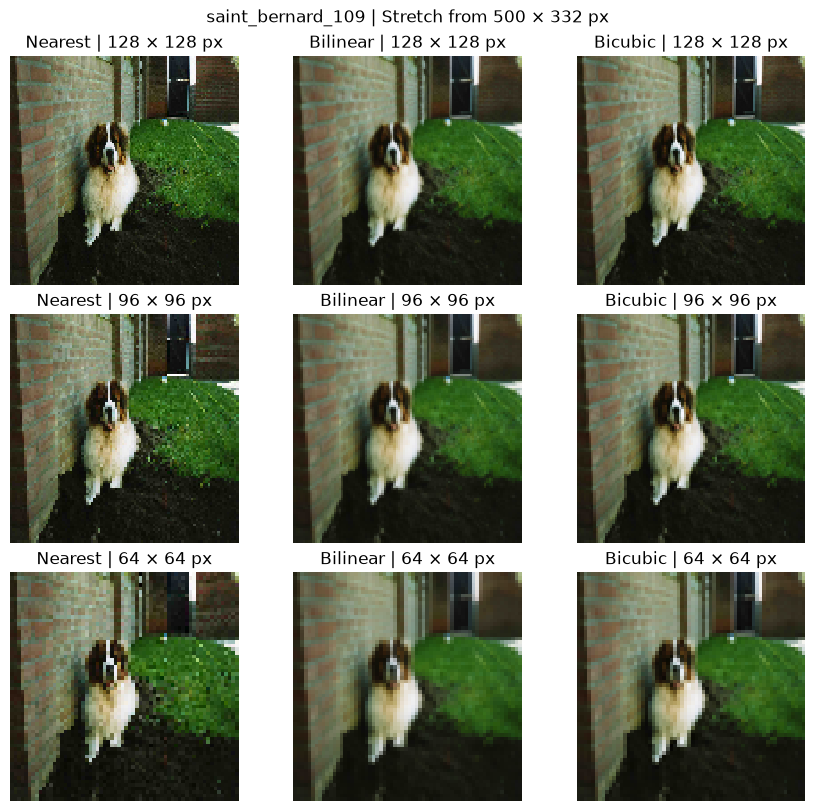

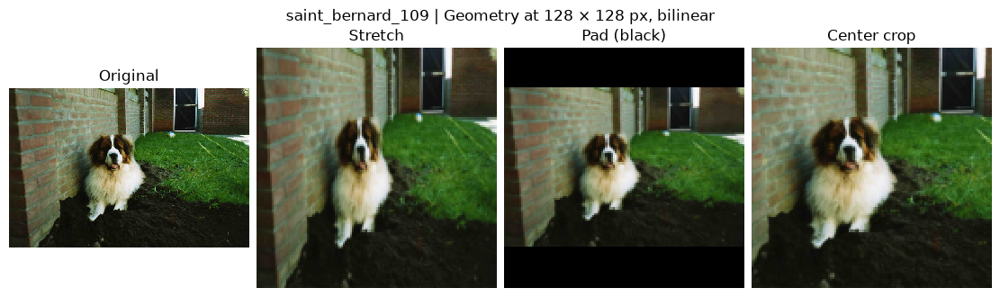

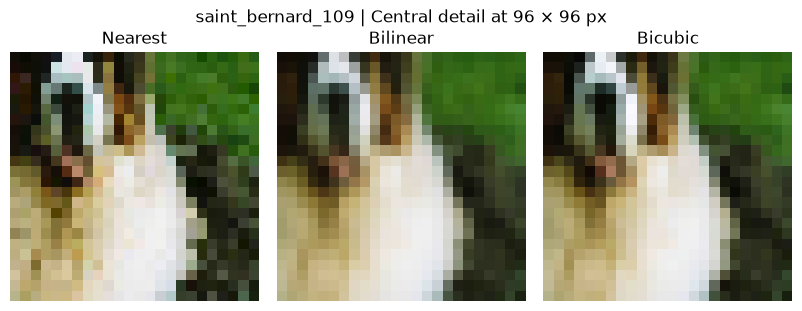


Persian_114 | 500 × 439 pixels
  Nearest 128 × 128: 0.40 ms
  Bilinear 128 × 128: 1.03 ms
  Bicubic 128 × 128: 1.69 ms
  Nearest 96 × 96: 0.21 ms
  Bilinear 96 × 96: 1.04 ms
  Bicubic 96 × 96: 1.61 ms
  Nearest 64 × 64: 0.48 ms
  Bilinear 64 × 64: 0.99 ms
  Bicubic 64 × 64: 1.59 ms
  Pad: 1.19 ms
  Center crop: 1.19 ms


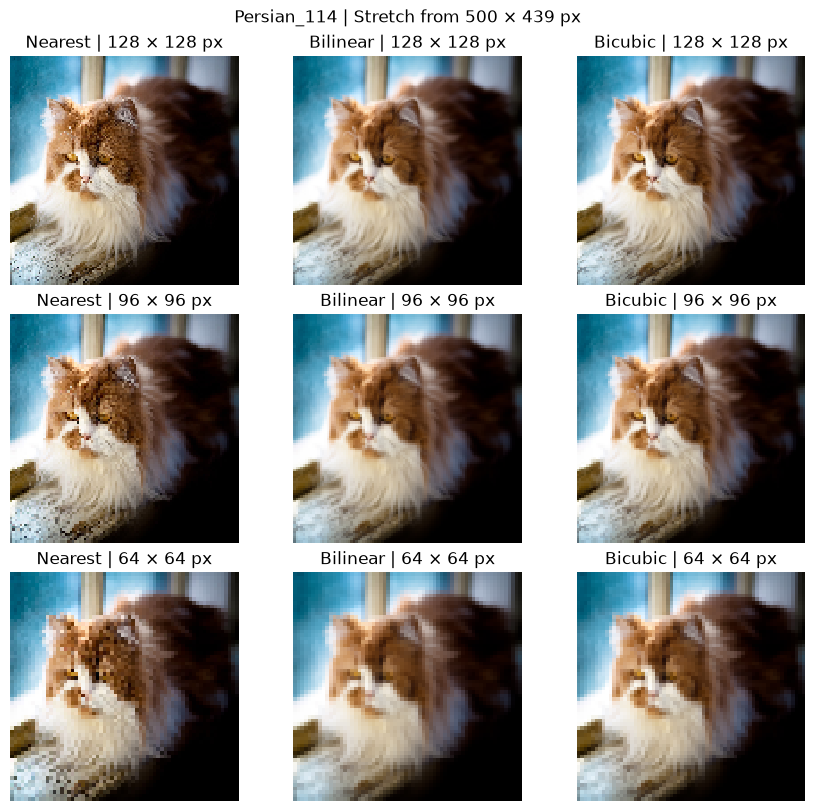

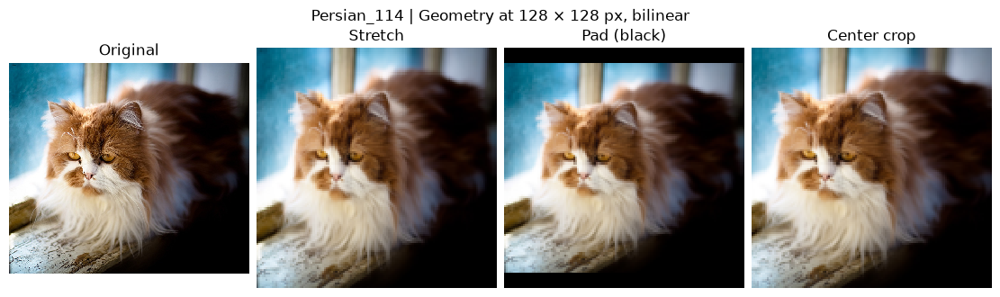


Bengal_112 | 500 × 436 pixels
  Nearest 128 × 128: 0.58 ms
  Bilinear 128 × 128: 1.06 ms
  Bicubic 128 × 128: 1.83 ms
  Nearest 96 × 96: 0.34 ms
  Bilinear 96 × 96: 0.96 ms
  Bicubic 96 × 96: 1.62 ms
  Nearest 64 × 64: 0.33 ms
  Bilinear 64 × 64: 0.85 ms
  Bicubic 64 × 64: 1.36 ms
  Pad: 1.09 ms
  Center crop: 1.06 ms


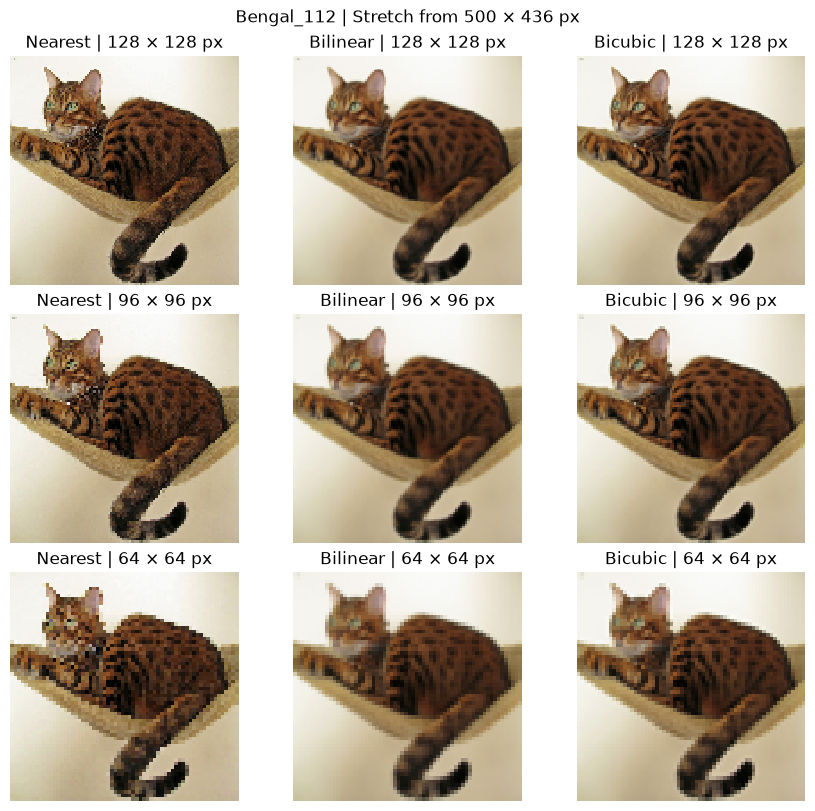

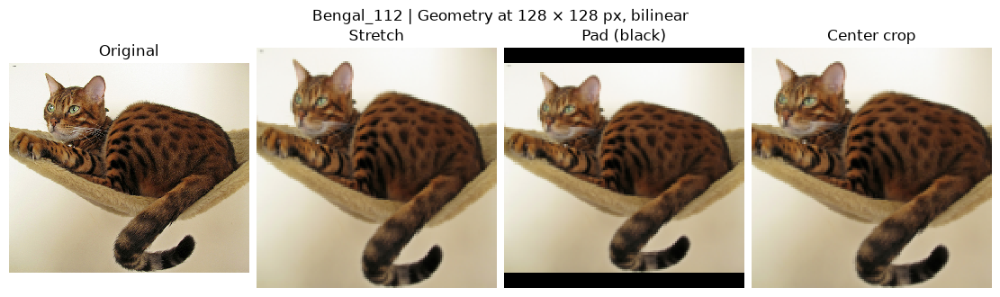

In [45]:
# Compare interpolation and geometry on the current TRAIN sample
resize_sizes = (128, 96, 64)
resize_methods = ("nearest", "bilinear", "bicubic")
geometry_size = 128
detail_size = 96
pad_colour = (0, 0, 0)

resize_variants = [
    (resize_title(size, method), resize_rgb, {
        "target_width": size, "target_height": size,
        "interpolation": method, "aspect_ratio_policy": "stretch",
    })
    for size in resize_sizes for method in resize_methods
]
resize_variants.extend([
    ("Pad", resize_rgb, {
        "target_width": geometry_size, "target_height": geometry_size, "interpolation": "bilinear",
        "aspect_ratio_policy": "pad", "padding_colour": pad_colour,
    }),
    ("Center crop", resize_rgb, {
        "target_width": geometry_size, "target_height": geometry_size, "interpolation": "bilinear",
        "aspect_ratio_policy": "center_crop",
    }),
])
print(f"Resize library: Pillow {pillow_version}")
compare_on_train(
    "resize", resize_variants,
    {
        "library": "Pillow", "library_version": pillow_version, "reducing_gap": None,
        "interpolation_comparison": {"square_sizes": resize_sizes, "methods": resize_methods, "policy": "stretch"},
        "geometry_comparison": {"size": [geometry_size, geometry_size], "interpolation": "bilinear",
                                "policies": ["stretch", "pad", "center_crop"], "padding_colour": pad_colour},
    },
    render=show_resize_comparisons,
)

## Per-image intensity normalisation

A z-score measures how far a value is from that image's mean in units of its population standard deviation. Compute z = (x − mean) / std over all RGB values of each image. For RGB values [0, 1, 2], the mean is 1, the standard deviation is √(2/3), and the z-scores are about [−1.225, 0, 1.225]. If std is at or below epsilon, the result is all zeros.

Shared statistics keep all three channels on the same scale and reduce sensitivity to a brightness or contrast change across the image. Removing the image's absolute level and scale can also remove brightness or colour cues that help separate breeds.

Dividing by 255 only changes units. Contrast stretching uses intensity endpoints. Feature standardisation operates on descriptor values, typically with statistics fitted on TRAIN. ImageNet normalisation uses fixed reference statistics for each channel. Here the result is signed float32, with statistics computed independently for each image.

Check that a descriptor can accept signed float32 before an accuracy experiment. A future pipeline could resize first and then normalise, with that order recorded explicitly. This notebook demonstrates each operation independently on the original TRAIN sample.

In [46]:
def intensity_statistics(values):
    return {
        "mean": float(values.mean(dtype=np.float64)),
        "std": float(values.std(dtype=np.float64, ddof=0)),
        "minimum": float(values.min()), "maximum": float(values.max()),
        "dtype": str(values.dtype),
    }


def count_signed_bins(values, edges):
    pixels = values.ravel()
    below = pixels < edges[0]
    above = pixels > edges[-1]
    bin_indices = np.searchsorted(edges, pixels[~(below | above)], side="right") - 1
    # Include the rightmost edge in the last bin.
    np.minimum(bin_indices, len(edges) - 2, out=bin_indices)
    counts = np.zeros(len(edges) - 1, dtype=np.int64)
    np.add.at(counts, bin_indices, 1)
    return counts, int(below.sum()), int(above.sum())


def show_normalisation_comparison(image_id, views, _sample_index):
    original, normalised = (image for _, image in views)
    original_stats = intensity_statistics(original)
    output_stats = intensity_statistics(normalised)
    for label, stats in (("Original", original_stats), ("True z-scores", output_stats)):
        print(f"  {label} ({stats['dtype']}): mean {stats['mean']:.5g}, std {stats['std']:.5g}, "
              f"min {stats['minimum']:.5g}, max {stats['maximum']:.5g}")

    preview = np.clip(0.5 + normalised / 6.0, 0.0, 1.0)
    counts, below, above = count_signed_bins(normalised, z_bin_edges)
    print(f"  Values outside the plotted range: {below:,} below −3, {above:,} above 3")

    figure, axes = plt.subplots(2, 2, figsize=(9, 6.5), layout="constrained")
    figure.suptitle(image_id)
    axes[0, 0].imshow(original)
    axes[0, 0].set_title("Original RGB")
    axes[0, 1].imshow(preview)
    axes[0, 1].set_title("Display only | z clipped to [−3, 3]")
    for axis in axes[0]:
        axis.set_axis_off()

    axes[1, 0].stairs(count_rgb_values(original).sum(axis=0), np.arange(257) - 0.5)
    axes[1, 0].set(xlim=(-0.5, 255.5), xlabel="Original intensity", ylabel="RGB value count")
    axes[1, 1].stairs(counts, z_bin_edges)
    axes[1, 1].set(xlim=(z_bin_edges[0], z_bin_edges[-1]), xlabel="True z-score", ylabel="RGB value count")
    plt.show()

    return figure, {
        "original_statistics": original_stats,
        "normalised_array_statistics": output_stats,
        "true_values_below_plot_range": below,
        "true_values_above_plot_range": above,
    }

RGB [0, 1, 2] -> z-scores: [-1.2247449  0.         1.2247449]

saint_bernard_109 | 500 × 332 pixels
  Per-image z-score: 4.46 ms
  Original (uint8): mean 67.599, std 54.149, min 0, max 255
  True z-scores (float32): mean -8.1964e-09, std 1, min -1.2484, max 3.4608
  Values outside the plotted range: 0 below −3, 5,626 above 3


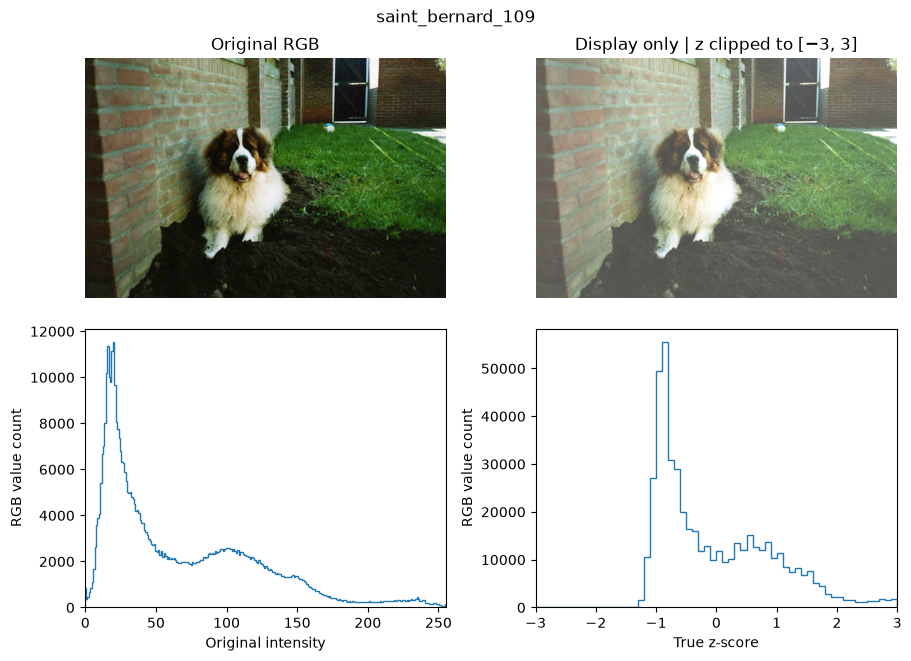


Persian_114 | 500 × 439 pixels
  Per-image z-score: 6.18 ms
  Original (uint8): mean 101.04, std 81.18, min 0, max 255
  True z-scores (float32): mean -8.0047e-09, std 1, min -1.2446, max 1.8966
  Values outside the plotted range: 0 below −3, 0 above 3


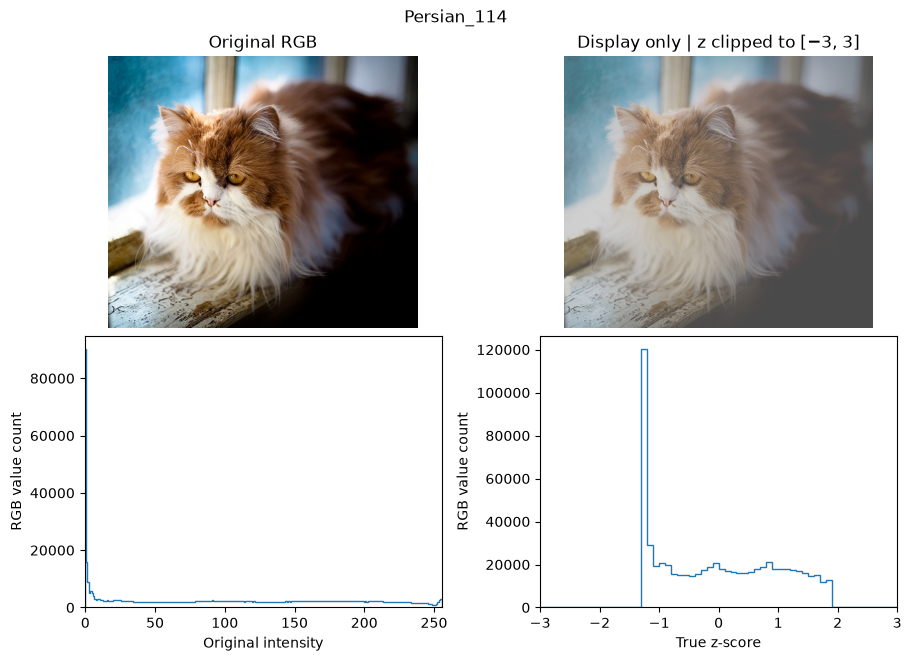


Bengal_112 | 500 × 436 pixels
  Per-image z-score: 5.67 ms
  Original (uint8): mean 141.42, std 80.611, min 0, max 255
  True z-scores (float32): mean -5.3399e-09, std 1, min -1.7543, max 1.409
  Values outside the plotted range: 0 below −3, 0 above 3


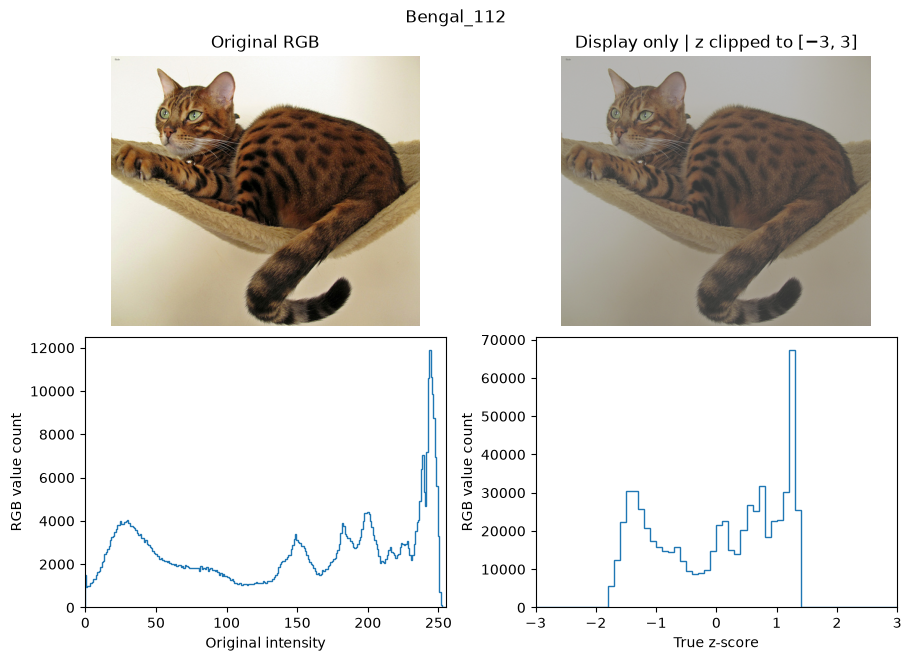

In [47]:
# Compare per-image z-scores on the current TRAIN sample
normalisation_epsilon = 1e-8
z_bin_edges = np.linspace(-3, 3, 61)
numerical_example = np.array([[[0, 1, 2]]], dtype=np.uint8)
print("RGB [0, 1, 2] -> z-scores:", normalise_intensity(numerical_example, epsilon=normalisation_epsilon)[0, 0])

compare_on_train(
    "intensity_normalisation",
    [("Per-image z-score", normalise_intensity, {"epsilon": normalisation_epsilon})],
    {
        "epsilon": normalisation_epsilon,
        "statistics_scope": "all RGB values within each image",
        "standard_deviation_ddof": 0,
        "original_histogram_bins": 256,
        "signed_histogram_bin_edges": z_bin_edges.tolist(),
        "true_output": {"dtype": "float32", "clipped": False, "saved_as_array": False},
        "figure_preview": {"display_only": True, "mapping": "clip(0.5 + z/6, 0, 1)", "displayed_z_range": [-3, 3]},
    },
    render=show_normalisation_comparison,
)

## Save operation evidence (optional)

This cell saves the operations you ran for the current sample. Edit the list if you want to save a subset. It writes timestamped PNGs and JSON under results/preprocessing/<operation>/ using the IDs recorded when each operation ran. The JSON includes software versions. Normalisation JSON describes the true float32 outputs and the display-only previews separately.

In [48]:
# Save operation evidence (optional)
operations_to_save = list(globals().get("comparison_results", {}))
if not operations_to_save:
    raise RuntimeError("Run an operation for the current TRAIN sample before saving.")

for operation in operations_to_save:
    save_train_comparison(operation)

Saved comparison figures and results/preprocessing/mean_filter/20261122T135856_084177Z_summary.json
Saved comparison figures and results/preprocessing/gaussian_filter/20261122T135857_992063Z_summary.json
Saved comparison figures and results/preprocessing/median_filter/20261122T135859_428792Z_summary.json
Saved comparison figures and results/preprocessing/contrast_stretching/20261122T135900_412485Z_summary.json
Saved comparison figures and results/preprocessing/histogram_equalisation/20261122T135901_793152Z_summary.json
Saved comparison figures and results/preprocessing/resize/20261122T135902_755355Z_summary.json
Saved comparison figures and results/preprocessing/intensity_normalisation/20261122T135904_595361Z_summary.json
